# Flu season: the calendar knows the rhythm, not the peak

**Flu comes every winter, so the first idea is to learn the season from the seasons before. On three winters of hospital admissions in 21 states, a forecaster built that way is well ahead in the one winter that kept to the usual week, and the worst of four in the two that came late. Four weeks before each peak, no forecaster here saw more than 62% of it. Generated seasons that repeat exactly show the forecaster is built right. Telling it the week of the peak, which nobody knows in time, shows what is missing: the timing is repaired, and the height of the peak stays open.**

A state health department plans beds and staff a few weeks ahead. The weeks that matter are the ones around the peak, and those are the weeks a backtest averaged over the whole winter says least about. This notebook keeps every forecast and asks where in the season each forecaster goes wrong, and why.

*Data: hospital admissions with confirmed flu in the United States by week and state, February 2022 to November 2026, from the FluSight forecast hub of the Centers for Disease Control and Prevention ([source and license](data/README.md#flu-admissions)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Four winters and a hole

The table has one row a week, ending on a Saturday, and one column for each state: the patients admitted to hospital that week with confirmed flu. Small counts jump around for reasons no forecaster can know, so this notebook keeps the 21 states that have no empty week and at least five admissions in every week from November to April. They hold three quarters of the country's admissions in those months.

The table covers four whole winters. Their peaks fall in different weeks, from the first week of December to the second week of February, and the highest is more than twice the lowest.

The quiet summer of 2024 is not a quiet summer. Hospitals had to report these counts until the spring of 2024 and again from 1 November 2024 ([reporting rules](https://www.cdc.gov/nhsn/psc/hospital-respiratory-reporting.html)). In between, reporting was voluntary and many stopped. Texas goes from 171 admissions to 89, 1 and 0 in four weeks. A forecaster that learned from those weeks would learn a reporting rule, so the test below is built so that no forecast reads them, and it checks that.

21 states, 249 weeks, weeks ending 05 February 2022 to 07 November 2026
They hold 74% of the country's admissions from November to April
2022-23: peak in the week ending 03 December 2022, 18,377 admissions
2023-24: peak in the week ending 30 December 2023, 16,839 admissions
2024-25: peak in the week ending 08 February 2025, 40,206 admissions
2025-26: peak in the week ending 03 January 2026, 30,899 admissions
A middle week from June to August: 2023 644, 2024 268, 2025 819
Texas, the four weeks to 18 May 2024: 171, 89, 1, 0


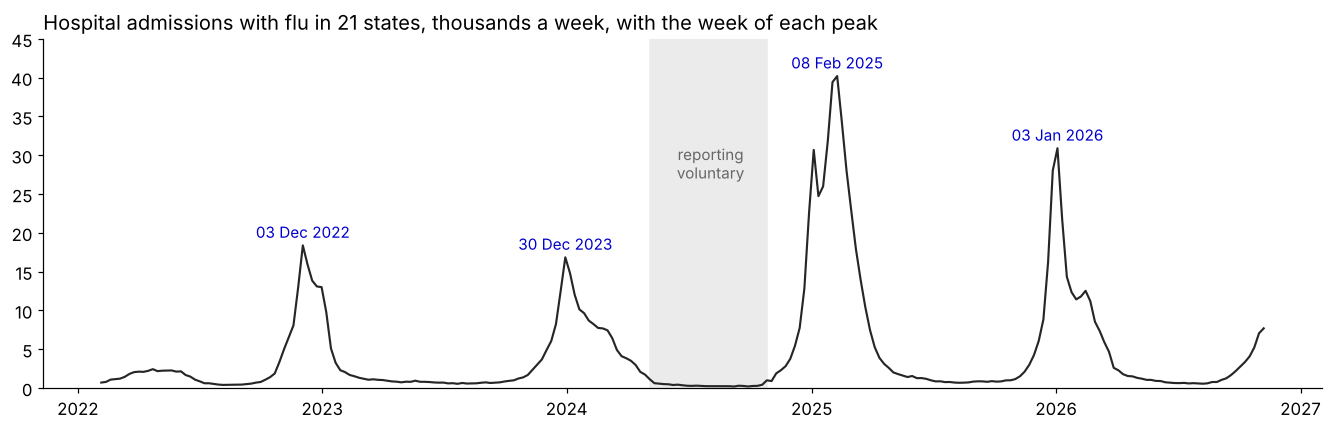

In [2]:
table = load("flu-admissions")
weeks = table.index
reported = table.drop(columns="United States").dropna(axis=1)
winter = (weeks >= "2022-11-01") & weeks.month.isin([11, 12, 1, 2, 3, 4])
admissions = reported.loc[:, reported[winter].min() >= 5]
total = admissions.sum(axis=1)
voluntary = (weeks >= "2024-05-01") & (weeks < "2024-11-01")

season = np.where(weeks.month >= 8, weeks.year, weeks.year - 1)     # a season runs from August to July
SEASONS = {2022: "2022-23", 2023: "2023-24", 2024: "2024-25", 2025: "2025-26"}
peak_row = {name: int(np.flatnonzero(season == start)[total[season == start].argmax()])
            for start, name in SEASONS.items()}

share = admissions[winter].sum().sum() / table.loc[winter, "United States"].sum()
print(f"{admissions.shape[1]} states, {len(weeks)} weeks, "
      f"weeks ending {weeks[0]:%d %B %Y} to {weeks[-1]:%d %B %Y}")
print(f"They hold {share:.0%} of the country's admissions from November to April")
for name, row in peak_row.items():
    print(f"{name}: peak in the week ending {weeks[row]:%d %B %Y}, {total.iloc[row]:,.0f} admissions")
summers = {year: total[(weeks >= f"{year}-06-01") & (weeks < f"{year}-09-01")].median()
           for year in (2023, 2024, 2025)}
print("A middle week from June to August: "
      + ", ".join(f"{year} {value:,.0f}" for year, value in summers.items()))
texas = table.loc["2024-04-27":"2024-05-18", "Texas"]
print("Texas, the four weeks to 18 May 2024: " + ", ".join(f"{value:.0f}" for value in texas))

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
ax.axvspan(weeks[voluntary][0], weeks[voluntary][-1], color="0.92")
ax.plot(total / 1000, color="0.15", linewidth=1.4)
for name, row in peak_row.items():
    ax.annotate(f"{weeks[row]:%d %b %Y}", (weeks[row], total.iloc[row] / 1000), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=10, color="#0000CC")
ax.text(weeks[voluntary][13], 27, "reporting\nvoluntary", ha="center", fontsize=10, color="0.4")
ax.set_ylim(0, 45)
ax.set_title("Hospital admissions with flu in 21 states, thousands a week, with the week of each peak")
plt.show()

assert admissions.shape == (249, 21) and table.shape == (249, 53) and table.isna().sum().sum() == 36
assert [f"{weeks[row]:%Y-%m-%d}" for row in peak_row.values()] == [
    "2022-12-03", "2023-12-30", "2025-02-08", "2026-01-03"]
assert [int(total.iloc[row]) for row in peak_row.values()] == [18377, 16839, 40206, 30899]
assert 0.73 < share < 0.76 and summers[2024] < 0.5 * min(summers[2023], summers[2025])
assert texas.tolist() == [171, 89, 1, 0]

A middle summer week in these states had 644 admissions in 2023 and 819 in 2025. In 2024 it had 268.

## Four forecasters

Flu moves by ratios: a week is half as high again as the week before, in a small state as in a large one. So everything below works on the logarithm of admissions, where a ratio becomes a difference, and reports a miss as a factor.

Each forecaster starts from last week's admissions in each state. They differ in the change they expect.

- **Last week** expects no change.
- **Own trend** carries on half of the latest weekly change, for each week ahead. Half, because a single week's change is a noisy guide.
- **Calendar** expects the change that the same weeks of the year brought in earlier seasons, averaged over three weeks and over all the states. About this season it knows only the date.
- **Calendar and trend** takes the calendar's change and adds half of the gap between this season's latest weekly change and the change the calendar expected for that week.

The class `Calendar` can also be given the rows of each season's peak. That is for a later section.

In [3]:
YEAR = 52                                # weeks from one season to the same week of the next


class LastWeek:
    def fit(self, history):
        self.last_ = history.to_numpy(float)[-1]
        return self

    def predict(self, dates):
        return np.tile(self.last_, (len(dates), 1))


class OwnTrend:
    # Last week, moved each week ahead by half of its latest weekly change.
    def fit(self, history):
        values = history.to_numpy(float)
        self.last_, self.step_ = values[-1], 0.5 * (values[-1] - values[-2])
        return self

    def predict(self, dates):
        ahead = np.arange(1, len(dates) + 1)[:, None]
        return self.last_ + ahead * self.step_


class Calendar:
    # Last week, moved by the change the same weeks brought in earlier seasons.
    def __init__(self, own=0.0, peaks=None):
        self.own = own                   # the share of this season's own departure to carry on
        self.peaks = peaks               # the row of every season's peak, if the forecaster is told

    def fit(self, history):
        self.values_ = history.to_numpy(float)
        return self

    def earlier(self, row):
        # The rows of earlier seasons that stand for this row.
        if self.peaks is None:           # the same week of the year
            rows = [row - YEAR * back for back in range(1, 10)]
        else:                            # as many weeks from the peak
            this = min(self.peaks, key=lambda peak: abs(peak - len(self.values_)))
            rows = [row - this + peak for peak in self.peaks if peak < this]
        return [found for found in rows if found >= 2]

    def usual(self, row):
        # The average weekly change over the three weeks around the row, in earlier seasons, all states.
        values = self.values_
        return np.mean([values[found + 1] - values[found - 2] for found in self.earlier(row)]) / 3

    def predict(self, dates):
        values, rows = self.values_, len(self.values_)
        ahead = np.arange(1, len(dates) + 1)[:, None]
        steps = np.cumsum([self.usual(rows + step) for step in range(len(dates))])[:, None]
        departure = (values[-1] - values[-2]) - self.usual(rows - 1)
        return values[-1] + steps + self.own * ahead * departure


forecasters = {"Last week": LastWeek(), "Own trend": OwnTrend(), "Calendar": Calendar(),
               "Calendar and trend": Calendar(own=0.5)}

## The test

Forecasts are made every Saturday from 22 November to 21 March, for each of the next four weeks, in three seasons: 2023-24, 2024-25 and 2025-26. The season of 2022-23 is there for the calendar to learn from. `cases_from_series` cuts the 52 forecast weeks once, and every forecaster runs on the same cases. The table has 21 columns, so each case gives 21 forecasts for each week ahead.

A miss is reported as a factor. Off by a factor of 1.5 means a forecast is typically 1.5 times the admissions that came, or the admissions 1.5 times the forecast.

The last lines of the cell check the promise about the summer of 2024. They cut the same cases from a table in which the 26 weeks of voluntary reporting hold nonsense, and so do the two other weeks in which one of the states had no admissions at all. Then every forecaster runs again. If no forecast changes, none of them read those weeks.

The first version of this notebook failed that check. It made forecasts until the end of March, and the last of them, four weeks ahead, borrowed from the calendar a week that ended in May 2024. So the forecast weeks stop on 21 March.

In [4]:
HORIZON = 4
logs = np.log(admissions.clip(lower=0.5))          # a week with no admissions counts as half of one

month_day = weeks.month * 100 + weeks.day
made = (weeks >= "2023-11-01") & ((month_day >= 1122) | (month_day <= 321))   # 22 November to 21 March
last_rows = np.flatnonzero(made)                   # the last week each forecast has seen
origins = [int(row) + 1 for row in last_rows]
cases = cases_from_series(logs, origins, horizon=HORIZON, name="flu")
made_in = np.array([SEASONS[start] for start in season[last_rows]])


def gaps(model, cases=cases):
    # Forecast less actual, in logarithms: forecast weeks by weeks ahead by states.
    run = Pipeline(model).run(cases=cases, keep_data=True)
    assert run.report.summary["status_counts"]["ERROR"] == 0
    return np.array([entry.forecast.point - np.asarray(entry.case.observed) for entry in run.cases])


def factor(gap):
    # The typical miss as a factor: 1.5 is a forecast 1.5 times the admissions, or the other way round.
    return float(np.exp(np.abs(gap).mean()))


gap = {name: gaps(model) for name, model in forecasters.items()}

DISTANCES = ["1 week", "2 weeks", "3 weeks", "4 weeks"]
TESTED = list(SEASONS.values())[1:]
by_distance = pd.DataFrame({name: [factor(found[:, step]) for step in range(HORIZON)]
                            for name, found in gap.items()}, index=DISTANCES).T
by_season = pd.DataFrame({name: {label: factor(found[made_in == label]) for label in TESTED}
                          for name, found in gap.items()}).T
print(f"{len(cases)} forecast weeks: "
      + ", ".join(f"{label} {(made_in == label).sum()}" for label in TESTED))
display(by_distance.round(2).rename_axis("Off by a factor of"))
display(by_season.round(2).rename_axis("Off by a factor of"))

# No forecast may read the summer of 2024 or a week with no admissions: put nonsense there, run again.
unread = voluntary | (admissions == 0).any(axis=1).to_numpy()
nonsense = logs.copy()
nonsense.loc[unread] = 99.0
again = cases_from_series(nonsense, origins, horizon=HORIZON, name="flu")
for name, model in forecasters.items():
    assert np.array_equal(gaps(model, again), gap[name])
print(f"{unread.sum()} weeks replaced with nonsense: no forecast changed")

assert len(cases) == 52 and unread.sum() == 28
assert np.allclose(by_distance.loc["Calendar and trend"], [1.24, 1.48, 1.77, 2.09], atol=0.015)
assert np.allclose(by_distance["4 weeks"], [2.40, 2.19, 2.37, 2.09], atol=0.015)
assert (by_distance.idxmin() == "Calendar and trend").all()
assert np.allclose(by_season.loc["Calendar"], [1.75, 2.04, 1.59], atol=0.015)
assert np.allclose(by_season["2025-26"], [1.99, 1.81, 1.59, 1.57], atol=0.015)
assert by_season["2023-24"].idxmax() == "Calendar" and by_season["2024-25"].idxmax() == "Calendar"

52 forecast weeks: 2023-24 17, 2024-25 17, 2025-26 18


,1 week,2 weeks,3 weeks,4 weeks
Off by a factor of,,,,
Last week,1.33,1.67,2.04,2.40
Own trend,1.25,1.53,1.85,2.19
Calendar,1.31,1.62,1.99,2.37
Calendar and trend,1.24,1.48,1.77,2.09


,2023-24,2024-25,2025-26
Off by a factor of,,,
Last week,1.54,1.95,1.99
Own trend,1.46,1.75,1.81
Calendar,1.75,2.04,1.59
Calendar and trend,1.52,1.75,1.57


28 weeks replaced with nonsense: no forecast changed


No forecaster is good at this. One week ahead the best is off by a factor of 1.24, and four weeks ahead by 2.09. Over all the weeks Calendar looks like a poor idea: four weeks ahead it is level with Last week (2.37 against 2.40) and behind Own trend. Calendar and trend is the best at every distance.

By season the calendar looks different. In 2025-26 the two forecasters that know the calendar are well ahead of the two that do not: 1.59 and 1.57 against 1.81 and 1.99. In the other two seasons plain Calendar is the worst of the four.

## Where in the season

Every forecast is kept, so the same run can be sorted by where the forecast week fell in its season: more than a week before the peak of the 21 states together, within a week of it, or after it. The second half of the table gives the middle forecast as a share of the admissions that came. Below 1, the forecasts were too low.

In [5]:
PARTS = ["Before", "Around", "After"]
target_rows = last_rows[:, None] + 1 + np.arange(HORIZON)
peak_of = np.array([peak_row[label] for label in made_in])[:, None]
part = np.where(target_rows < peak_of - 1, "Before", np.where(target_rows <= peak_of + 1, "Around", "After"))


def reads(gap):
    # The middle forecast as a share of the admissions that came.
    return float(np.exp(np.median(gap)))


by_part = pd.DataFrame({name: {(title, where): measure(found[part == where])
                               for title, measure in [("Off by a factor of", factor),
                                                      ("Forecast as a share of actual", reads)]
                               for where in PARTS}
                        for name, found in gap.items()}).T
display(by_part.round(2))
scored = [(part == where).sum() * admissions.shape[1] for where in PARTS]
print(f"Forecasts scored: {scored[0]:,} before the peak, {scored[1]:,} around it, {scored[2]:,} after")

late = {}
for start, label in SEASONS.items():
    before = [(name, row) for name, row in peak_row.items() if row < peak_row[label]]
    if before:
        expected = np.mean([row + YEAR * (start - int(name[:4])) for name, row in before])
        late[label] = float(peak_row[label] - expected)
print("Weeks the peak came after the average week of the earlier peaks:\n    "
      + ", ".join(f"{label} {value:+.1f}" for label, value in late.items()))

low = by_part["Forecast as a share of actual"]
assert np.allclose(low.loc["Calendar"], [0.57, 0.50, 1.24], atol=0.015)
assert np.allclose(low.loc["Last week"], [0.55, 0.59, 1.45], atol=0.015)
assert low[["Before", "Around"]].max().max() < 0.83 and low["Around"].idxmin() == "Calendar"
assert np.allclose(list(late.values()), [4.0, 8.0, 0.33], atol=0.05)

Off by a factor of               \
                               Before Around After   
Last week                        2.19   2.04  1.64   
Own trend                        1.78   1.73  1.61   
Calendar                         2.04   2.16  1.60   
Calendar and trend               1.72   1.79  1.52   

                   Forecast as a share of actual               
                                          Before Around After  
Last week                                   0.55   0.59  1.45  
Own trend                                   0.74   0.81  1.28  
Calendar                                    0.57   0.50  1.24  
Calendar and trend                          0.70   0.73  1.19

Forecasts scored: 966 before the peak, 756 around it, 2,646 after
Weeks the peak came after the average week of the earlier peaks:
    2023-24 +4.0, 2024-25 +8.0, 2025-26 +0.3


Before the peak and around it every forecaster reads low: the middle forecast was between 50% and 81% of the admissions that came. Last week reads low on the way up and high on the way down, as any forecaster does that expects no change. Calendar is the lowest of all around the peak, at half of the admissions that came.

The last line says why. The peak of 2023-24 came four weeks later than the peak before it, and the peak of 2024-25 came eight weeks later than the average of the two before. A forecaster that follows the calendar expected the fall to have begun while admissions were still climbing. In 2025-26 the peak came within half a week of the average of the three earlier ones, and that is the season in which the calendar was worth having.

## Four weeks before

The picture shows the last two seasons: the admissions in the 21 states together, and the forecast made for each week four weeks before, by Calendar and by Calendar and trend. The table under it takes the peak week of each season and gives the forecast made four weeks before as a percentage of the admissions that came.

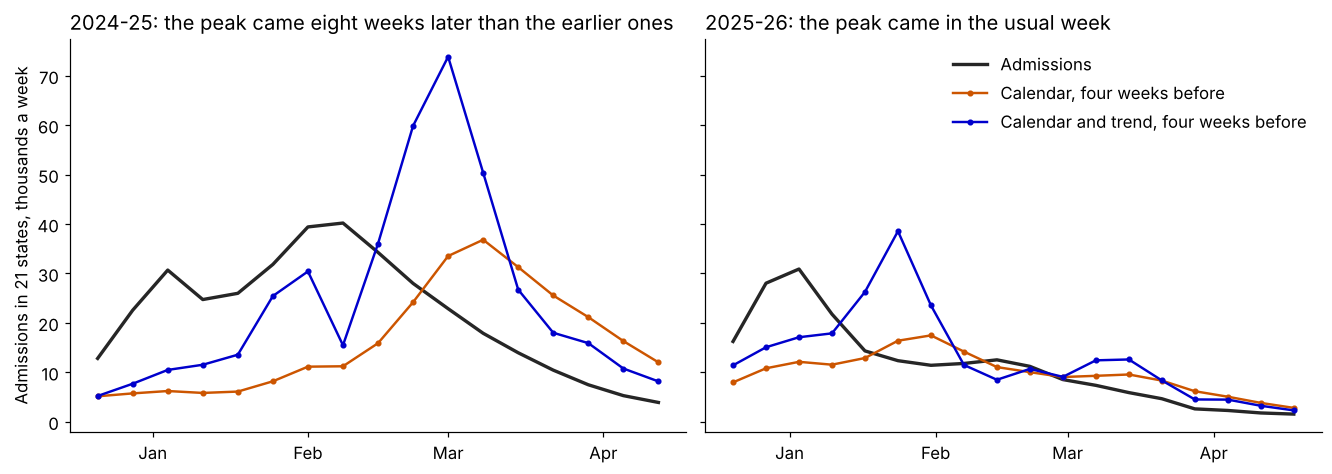

,2023-24,2024-25,2025-26
% of the peak week,,,
Last week,29,61,20
Own trend,58,45,43
Calendar,21,28,39
Calendar and trend,28,38,55


Calendar and trend, its highest forecast of 2024-25: 74 thousand
    for the week ending 01 March 2025, which had 23 thousand


In [6]:
actual = logs.to_numpy()[target_rows]              # forecast weeks by weeks ahead by states
ahead_4 = {name: np.exp(actual + gap[name]).sum(axis=2)[:, -1] / 1000
           for name in ["Calendar", "Calendar and trend"]}
came = np.exp(actual).sum(axis=2)[:, -1] / 1000

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", sharey=True)
titles = {"2024-25: the peak came eight weeks later than the earlier ones": "2024-25",
          "2025-26: the peak came in the usual week": "2025-26"}
for ax, (title, label) in zip(axes, titles.items()):
    rows = made_in == label
    when = weeks[target_rows[rows, -1]]
    ax.plot(when, came[rows], color="0.15", linewidth=2.2, label="Admissions")
    ax.plot(when, ahead_4["Calendar"][rows], color="#CC5500", linewidth=1.6, marker="o", markersize=3,
            label="Calendar, four weeks before")
    ax.plot(when, ahead_4["Calendar and trend"][rows], color="#0000CC", linewidth=1.6, marker="o",
            markersize=3, label="Calendar and trend, four weeks before")
    ax.set_title(title)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set_ylabel("Admissions in 21 states, thousands a week")
axes[1].legend(loc="upper right")
plt.show()


def peak_share(name):
    # The peak week of the 21 states together: the forecast made four weeks before, over the admissions.
    shares = {}
    for label in TESTED:
        case = int(np.flatnonzero(target_rows[:, -1] == peak_row[label])[0])
        forecast = np.exp(actual[case, -1] + gap[name][case, -1]).sum()
        shares[label] = float(forecast / np.exp(actual[case, -1]).sum() * 100)
    return shares


seen = pd.DataFrame({name: peak_share(name) for name in forecasters}).T
display(seen.round(0).astype(int).rename_axis("% of the peak week"))
highest = int(np.argmax(np.where(made_in == "2024-25", ahead_4["Calendar and trend"], 0)))
print(f"Calendar and trend, its highest forecast of 2024-25: "
      f"{ahead_4['Calendar and trend'][highest]:.0f} thousand\n    for the week ending "
      f"{weeks[target_rows[highest, -1]]:%d %B %Y}, which had {came[highest]:.0f} thousand")

assert seen.max().max() < 62 and (seen < 50).sum().sum() == 9
assert seen.round(0).loc["Calendar"].tolist() == [21, 28, 39]
assert round(ahead_4["Calendar and trend"][highest]) == 74 and round(came[highest]) == 23

Four weeks ahead, both forecasts trail the season by about a month. In 2024-25 Calendar forecast 28% of the peak week, and then went on rising for four weeks after the season had turned. Calendar and trend saw more of the climb and paid for it afterward: it carried the climb on and forecast 74 thousand admissions for a week of March that had 23 thousand. In 2025-26, with the peak in the usual week, Calendar was close from February on, Calendar and trend overshot once more on the way down, and both were far below the peak itself. Four weeks before a peak, no forecaster here saw more than 62% of it, and most saw less than half.

## Is the forecaster wrong, or did the season move?

A forecaster that fails could simply be built wrong. That can be checked where the answer is known. TimeGym generates seasons that repeat exactly: the same wave every 52 weeks, with a peak about 50 times the summer level, as in these states, plus surprises that stay, of the size of one week's surprise in the flu data. The series stand for the logarithm of admissions, like the table the forecasters ran on. On them the calendar is right by construction, each forecaster has three earlier seasons to learn from, and TimeGym knows the best possible forecast, the answer key.

In [7]:
summer = {year: admissions[(weeks >= f"{year}-06-01") & (weeks < f"{year}-09-01")].median()
          for year in (2023, 2025)}
peak_over_summer = {year: float((admissions[season == year].max() / low_level).median())
                    for year, low_level in summer.items()}
surprise = float(np.abs(gap["Calendar and trend"][:, 0]).mean() / np.sqrt(2 / np.pi))
print("A state's peak over its middle summer week: "
      + ", ".join(f"{year} {value:.0f} times" for year, value in peak_over_summer.items()))
print(f"The size of one week's surprise, in logarithms: {surprise:.2f}")

PEAK = 13 + 3 * YEAR                     # the wave's fourth peak, after three seasons to learn from
wave = {"intercept": 7.0, "slope": 0.0, "amplitude": np.log(50) / 2, "period": float(YEAR),
        "phase": 0.0, "sigma": round(surprise, 2), "residual": "random_walk"}
spots = range(PEAK - 8, PEAK + 11)       # the last week seen: from 8 weeks before the peak to 10 after
repeating = [Scenario("composite", history_length=row + 1, horizon=HORIZON, parameters=wave)
             for row in spots]
SERIES = 100

wave_gap = {}
for name, model in forecasters.items():
    run = Pipeline(model).run(scenarios=repeating, instances=SERIES, seed=0, keep_data=True)
    assert run.report.summary["status_counts"]["ERROR"] == 0
    assert len({entry.case.manifest["seed"] for entry in run.cases}) == SERIES
    truth = np.array([np.asarray(entry.case.observed)[:, 0] for entry in run.cases])
    wave_gap[name] = np.array([entry.forecast.point[:, 0] for entry in run.cases]) - truth
    key = np.array([np.asarray(entry.case.reference.mean)[:, 0] for entry in run.cases]) - truth
    last_seen = np.array([len(entry.case.task.history) - 1 for entry in run.cases])
wave_gap["Answer key"] = key

wave_rows = last_seen[:, None] + 1 + np.arange(HORIZON)
wave_part = np.where(wave_rows < PEAK - 1, "Before", np.where(wave_rows <= PEAK + 1, "Around", "After"))
on_wave = pd.DataFrame({name: {**{("Off by a factor of", distance): factor(found[:, step])
                                  for step, distance in enumerate(DISTANCES)},
                               **{("Forecast as a share of actual", where): reads(found[wave_part == where])
                                  for where in PARTS}}
                        for name, found in wave_gap.items()}).T
display(on_wave.round(2))

far = on_wave[("Off by a factor of", "4 weeks")]
level = on_wave["Forecast as a share of actual"]
assert 35 < peak_over_summer[2023] < 45 and 55 < peak_over_summer[2025] < 65 and round(surprise, 2) == 0.27
assert np.allclose(far[["Calendar", "Calendar and trend", "Answer key"]], [1.62, 1.93, 1.52], atol=0.015)
assert far.drop("Answer key").idxmin() == "Calendar"
assert np.allclose(level.loc["Calendar"], [1.00, 1.05, 1.06], atol=0.015)
assert np.allclose(level.loc["Last week", ["Before", "After"]], [0.77, 1.47], atol=0.015)

A state's peak over its middle summer week: 2023 40 times, 2025 60 times
The size of one week's surprise, in logarithms: 0.27


Off by a factor of                          \
                               1 week 2 weeks 3 weeks 4 weeks   
Last week                        1.28    1.48    1.70    1.95   
Own trend                        1.28    1.49    1.72    1.97   
Calendar                         1.26    1.40    1.52    1.62   
Calendar and trend               1.28    1.48    1.70    1.93   
Answer key                       1.24    1.36    1.45    1.52   

                   Forecast as a share of actual               
                                          Before Around After  
Last week                                   0.77   0.95  1.47  
Own trend                                   0.94   1.08  1.25  
Calendar                                    1.00   1.05  1.06  
Calendar and trend                          1.03   1.05  1.03  
Answer key                                  1.00   1.03  1.05

On seasons that repeat, Calendar is the best of the four and close to the best possible: off by a factor of 1.62 four weeks ahead, where the answer key is off by 1.52. It reads level before, around and after the peak. So its low readings on flu are not built into the forecaster. They come from the seasons. Last week reads low before the peak and high after it here too, so that part of its miss on flu is built in.

The same table puts a price on the trend half of Calendar and trend. When seasons repeat it is a cost: 1.93 against 1.62 four weeks ahead. On flu it paid in the two seasons that came late, and cost nothing that shows in the third (1.57 against 1.59).

These generated seasons are tamer than flu. The wave is smooth where flu turns within two or three weeks, and its surprises are all of one kind. They test the forecaster, and they are not a model of flu.

## What would knowing the peak week be worth?

Calendar lines earlier seasons up by date. Suppose it could line them up peak over peak, because someone told it the week in which this season peaks. Nobody knows that in time. The idea is the one in [Train station riders](station-riders.ipynb): hand the forecaster the truth about one thing and see how much of the miss that one thing explains. The cases are the same, and so is the check with nonsense in the unreliable weeks.

In [8]:
TOLD = "Calendar, told the peak week"
told = Calendar(peaks=sorted(peak_row.values()))
gap[TOLD] = gaps(told)
assert np.array_equal(gaps(told, again), gap[TOLD])

rows = {}
for name in ["Calendar", "Calendar and trend", TOLD]:
    rows[name] = {**{("Off by a factor of", distance): factor(gap[name][:, step])
                     for step, distance in enumerate(DISTANCES)},
                  **{("Share of actual", where): reads(gap[name][part == where]) for where in PARTS}}
with_told = pd.DataFrame(rows).T
display(with_told.round(2))
seen.loc[TOLD] = peak_share(TOLD)
display(seen.round(0).astype(int).rename_axis("% of the peak week"))


def more(first, second, step=None):
    # How much larger the first forecaster's typical miss is, in percent, with a 95% interval.
    pick = slice(None) if step is None else [step]
    weekly = (np.abs(gap[first][:, pick]).mean(axis=(1, 2))
              - np.abs(gap[second][:, pick]).mean(axis=(1, 2)))
    result = paired_t_interval(weekly)
    return [float(np.expm1(value) * 100) for value in (result["mean"], *result["ci95"])]


behind = {}
for first, second, step in [("Calendar", TOLD, None), ("Calendar and trend", TOLD, None),
                            ("Calendar and trend", TOLD, HORIZON - 1),
                            ("Calendar", "Calendar and trend", None),
                            ("Own trend", "Calendar and trend", None)]:
    distance = "all distances" if step is None else "4 weeks"
    behind[first, second, step] = percent, low_end, high_end = more(first, second, step)
    print(f"{first} against {'told the week' if second == TOLD else second}, {distance}: "
          f"{percent:+.0f}% ({low_end:+.0f} to {high_end:+.0f})")

assert np.allclose(with_told.loc[TOLD], [1.25, 1.46, 1.65, 1.83, 0.90, 0.99, 1.02], atol=0.015)
assert seen.round(0).loc[TOLD].tolist() == [93, 196, 47]
assert np.allclose(behind["Calendar", TOLD, None], [16, 6, 27], atol=0.6)
assert np.allclose(behind["Calendar and trend", TOLD, None], [5, -2, 13], atol=0.6)
assert np.allclose(behind["Calendar and trend", TOLD, HORIZON - 1], [14, 1, 29], atol=0.6)
assert behind["Calendar", "Calendar and trend", None][1] > 0
assert behind["Own trend", "Calendar and trend", None][1] < 0

Off by a factor of                          \
                                         1 week 2 weeks 3 weeks 4 weeks   
Calendar                                   1.31    1.62    1.99    2.37   
Calendar and trend                         1.24    1.48    1.77    2.09   
Calendar, told the peak week               1.25    1.46    1.65    1.83   

                             Share of actual               
                                      Before Around After  
Calendar                                0.57   0.50  1.24  
Calendar and trend                      0.70   0.73  1.19  
Calendar, told the peak week            0.90   0.99  1.02

,2023-24,2024-25,2025-26
% of the peak week,,,
Last week,29,61,20
Own trend,58,45,43
Calendar,21,28,39
Calendar and trend,28,38,55
"Calendar, told the peak week",93,196,47


Calendar against told the week, all distances: +16% (+6 to +27)
Calendar and trend against told the week, all distances: +5% (-2 to +13)
Calendar and trend against told the week, 4 weeks: +14% (+1 to +29)
Calendar against Calendar and trend, all distances: +10% (+4 to +17)
Own trend against Calendar and trend, all distances: +4% (-1 to +9)


Told the peak week, the forecaster reads close to level in every part of the season (0.90, 0.99 and 1.02), and its miss four weeks ahead falls from a factor of 2.37 to 1.83. So the way a season climbs to its peak and falls away does carry over from earlier seasons. The week does not carry over.

Neither does the height. Told the week, the forecast of the peak made four weeks before was 93% of the admissions that came in 2023-24, 196% in 2024-25 and 47% in 2025-26.

A forecaster gets part of this without being told. Over all four distances, Calendar and trend is 5% behind the forecaster that knows the peak week, with an interval from 2% ahead to 13% behind, so three seasons cannot tell the two apart. Four weeks ahead it is 14% behind (1% to 29%). Plain Calendar is 16% behind (6% to 27%), and clearly behind Calendar and trend as well. Own trend cannot be told from Calendar and trend over all the weeks.

For the health department the result is about how far to trust a forecast. One week ahead, the calendar together with the season's own trend is off by a factor of 1.24, which is something to plan with. Four weeks ahead it is off by a factor of 2, and before a peak it is too low: in every season here, the forecast made four weeks before the peak was well under what came. Plans for the peak need a margin that these counts cannot supply.

## What TimeGym added

- **Every forecast kept, so one run gave every view.** The tables by distance, by season and by part of the season, and the forecasts of the peak week, all come from the same 52 cases. The average over all the weeks said the calendar was not worth having. The split by season said when it is.
- **A check that fails on bad data.** Cutting the same cases from a table with nonsense in the unreliable weeks caught a forecast that read one of them, before any number was reported.
- **A known answer.** On generated seasons that repeat, the answer key gave the best possible miss. Calendar came close to it, which put the blame for its misses on flu's seasons, and the same run priced the trend half.
- **One thing told.** A forecaster is any class with `fit` and `predict`, so it can hold what it is told. The pipeline still hands it only the past, and the cases did not change.
- **Twenty-one series in one run.** A table with 21 columns gives 21 forecasts a case, and the forecast of all the states together is their sum.

## Change one thing

- Set `own=1.0` in `Calendar`, and use the whole of the latest change in `OwnTrend`. Is half the better share at every distance?
- Tell the forecaster a peak week for 2024-25 that is two weeks too early. How much of that season's gain is left?
- Lower the bar from five admissions to one, which brings in twelve more states. What happens to the factors?
- Run the four forecasters on the column `United States` alone. Is the whole country easier than a state?
- Score only the forecasts made before the peak.

**What this doesn't show.** Three seasons are three peaks. The 52 forecast weeks and 21 states are far fewer independent tries than they look, because states rise and fall together and neighboring weeks share a season, so the intervals are too narrow and nothing here is settled. The counts are today's version: the source says they are revised after they are first published, so a forecaster at the time saw less complete figures for the latest weeks than this test gives it. Reporting only became required again on 1 November 2024, so the first forecasts of 2024-25, made three weeks later, may start from counts that were still filling in. The forecasters are four simple rules; the hub the data comes from collects forecasts from many teams every week, and none of them is scored here. The states are the 21 with the most admissions. And "told the peak week" uses the peak of all 21 states together as it turned out, while single states peak a week or two apart.

**Related:** [Train station riders](station-riders.ipynb) uses the same move, telling the forecaster the truth about one thing, for the weather. [The sunspot cycle](sunspots.ipynb) and [El Niño](el-nino.ipynb) ask how far ahead a forecast of an irregular cycle is worth making. [Tomorrow's air in London](air-quality.ipynb) is about data that looks complete and is not. [A custom model](../tutorials/02_custom_model.ipynb) shows the two methods a forecaster needs, and [Multivariate forecasting](../tutorials/06_multivariate_forecasting.ipynb) covers tables with several series. More examples are on the [examples page](../docs/examples.md).